# 01 — Exploratory Data Analysis & Baselines
## MURA v1.1: Musculoskeletal Radiograph Abnormality Triage

**Course:** AIE231 — Neural Networks (Alamein International University)  
**Checkpoints Covered:** Checkpoint 1 (Problem Formulation & Setup) + Checkpoint 2 (EDA, Leak-Free Splits & Baselines)

---

## 1. Problem Formulation & Primary Metric Justification

Emergency clinicians and radiologists routinely review large queues of musculoskeletal X-ray studies where delayed recognition of fractures, dislocations, or hardware complications risks permanent functional impairment. This project frames musculoskeletal radiograph triage as a **binary image classification task** predicting whether a radiographic view shows a **Normal (`0`)** or **Abnormal (`1`)** musculoskeletal study. Because false negatives (missed abnormalities) delay urgent orthopedic intervention whereas false positives only trigger priority radiologist review, the clinical error cost is strongly asymmetric.

- **Input Shape:** `(224, 224, 3)` RGB float32 tensor rescaled to `[0, 1]` (resized from raw variable-dimension PNG radiographs; grayscale images converted consistently to 3 channels for ImageNet-pretrained backbones).
- **Output:** Single sigmoid probability $p = P(\text{Abnormal} \mid x) \in [0, 1]$.
- **Loss Function:** Binary Cross-Entropy weighted by inverse training class frequency (`class_weight='balanced'`).
- **Primary Metric:** **Cohen's Kappa ($\kappa$)** — measures inter-rater agreement beyond chance and is the official benchmark metric of the Stanford MURA competition. Unlike raw accuracy (which rewards predicting the ~60% majority Normal class with $\kappa = 0$), $\kappa$ penalizes trivial majority-class collapse. Alongside $\kappa$, we track **Abnormal Recall (Sensitivity)** and **Macro-F1** to directly enforce low false-negative clinical risk.

In [1]:
import hashlib
import os
import pathlib
import warnings
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image

warnings.filterwarnings("ignore")

PROJECT_ROOT = pathlib.Path().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import (
    build_dataframe,
    clean_dataframe,
    compute_weights,
    load_config,
    load_flattened_images,
    patient_stratified_split,
    resolve_data_root,
    set_global_seed,
)
from src.evaluate import evaluate_study_level, get_confusion_matrix
from src.models import LogisticBaseline, MajorityBaseline

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
EXP_DIR = PROJECT_ROOT / "experiments"
EXP_DIR.mkdir(parents=True, exist_ok=True)

cfg = load_config(str(PROJECT_ROOT / "configs" / "exp_baseline.yaml"))
set_global_seed(int(cfg.get("seed", 42)))
DATA_ROOT = resolve_data_root(cfg)
print(f"Project root : {PROJECT_ROOT}")
print(f"Dataset root : {DATA_ROOT} (exists={os.path.isdir(DATA_ROOT)})")

Project root : C:\Users\bdbdr\.gemini\antigravity\scratch\aie231-mura-abnormality-triage
Dataset root : C:\Users\bdbdr\Downloads\archive\MURA-v1.1 (exists=True)


## 2. Dataset Overview & Manifest Verification

In [2]:
df_train_raw = build_dataframe(
    DATA_ROOT,
    cfg["data"]["train_image_paths"],
    labeled_studies_csv=cfg["data"]["train_labels"],
)
df_valid_raw = build_dataframe(
    DATA_ROOT,
    cfg["data"]["valid_image_paths"],
    labeled_studies_csv=cfg["data"]["valid_labels"],
)

train_patients_all = set(df_train_raw["patient_id"])
valid_patients_all = set(df_valid_raw["patient_id"])

summary = pd.DataFrame([
    {
        "Official Split": "Train",
        "Images": len(df_train_raw),
        "Studies": df_train_raw["study_id"].nunique(),
        "Patients": len(train_patients_all),
        "Normal Images (%)": round((1 - df_train_raw["label"].mean()) * 100, 2),
        "Abnormal Images (%)": round(df_train_raw["label"].mean() * 100, 2),
    },
    {
        "Official Split": "Valid (Held-out Benchmark)",
        "Images": len(df_valid_raw),
        "Studies": df_valid_raw["study_id"].nunique(),
        "Patients": len(valid_patients_all),
        "Normal Images (%)": round((1 - df_valid_raw["label"].mean()) * 100, 2),
        "Abnormal Images (%)": round(df_valid_raw["label"].mean() * 100, 2),
    },
])
print(summary.to_string(index=False))
print(f"\nPatient overlap between official train & valid: {len(train_patients_all & valid_patients_all)}")
multi_bp = (df_train_raw.groupby("patient_id")["body_part"].nunique() > 1).sum()
print(f"Train patients scanned across >1 body part: {multi_bp:,}")

            Official Split  Images  Studies  Patients  Normal Images (%)  Abnormal Images (%)
                     Train   36808    13457     11184              59.59                40.41
Valid (Held-out Benchmark)    3197     1199       783              52.14                47.86

Patient overlap between official train & valid: 0
Train patients scanned across >1 body part: 1,467


## 3. Class Distribution (Image-Level & Study-Level)

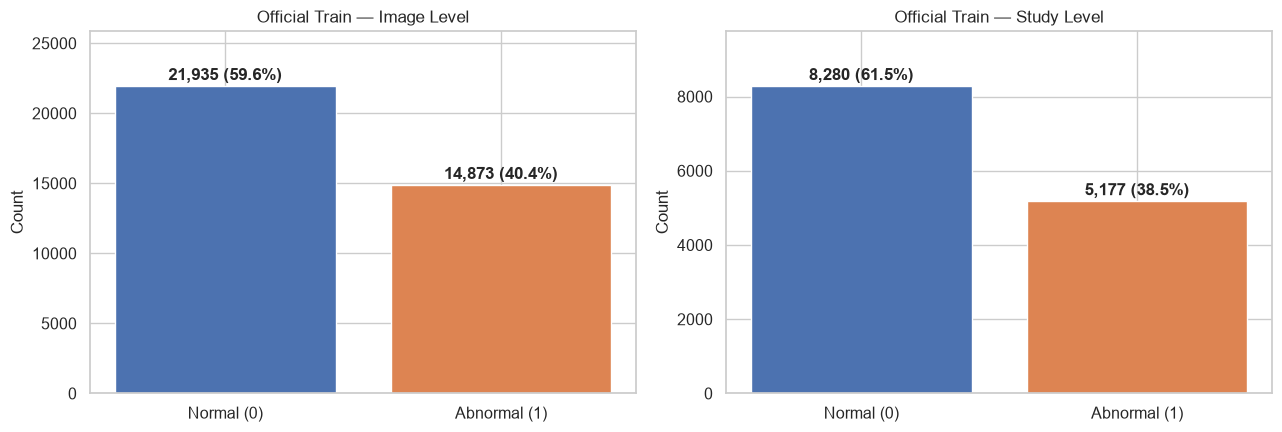

Image-level ratio (Normal:Abnormal) = 1.47 : 1
Study-level ratio (Normal:Abnormal) = 1.60 : 1


In [3]:
train_studies = df_train_raw.groupby("study_id", as_index=False)["label"].first()
valid_studies = df_valid_raw.groupby("study_id", as_index=False)["label"].first()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
panels = [
    ("Official Train — Image Level", df_train_raw["label"]),
    ("Official Train — Study Level", train_studies["label"]),
]
for ax, (title, series) in zip(axes, panels):
    counts = series.value_counts().sort_index()
    bars = ax.bar(["Normal (0)", "Abnormal (1)"], counts.values, color=["#4C72B0", "#DD8452"])
    ax.set_title(title)
    ax.set_ylabel("Count")
    ax.set_ylim(0, counts.max() * 1.18)
    for bar, val in zip(bars, counts.values):
        pct = val / counts.sum() * 100
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + counts.max() * 0.02,
                f"{val:,} ({pct:.1f}%)", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig(EXP_DIR / "eda_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

img_counts = df_train_raw["label"].value_counts()
st_counts = train_studies["label"].value_counts()
print(f"Image-level ratio (Normal:Abnormal) = {img_counts[0] / img_counts[1]:.2f} : 1")
print(f"Study-level ratio (Normal:Abnormal) = {st_counts[0] / st_counts[1]:.2f} : 1")

## 4. Body-Part Distribution & Feature-Label Correlations

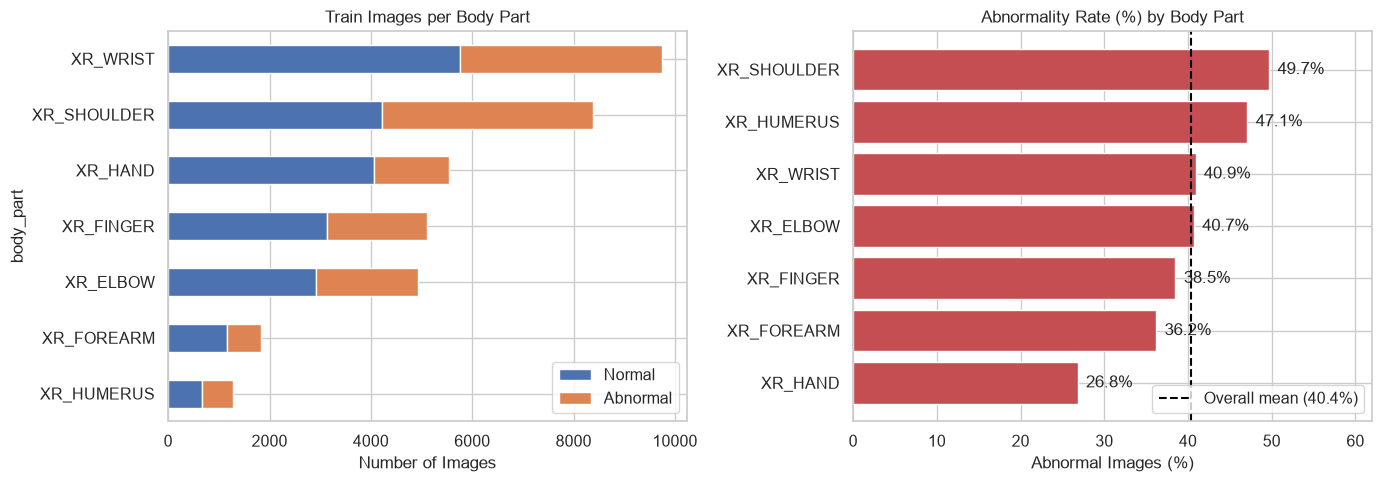

             Normal  Abnormal  Total  Abnormal_%
body_part                                       
XR_WRIST       5765      3987   9752        40.9
XR_SHOULDER    4211      4168   8379        49.7
XR_HAND        4059      1484   5543        26.8
XR_FINGER      3138      1968   5106        38.5
XR_ELBOW       2925      2006   4931        40.7
XR_FOREARM     1164       661   1825        36.2
XR_HUMERUS      673       599   1272        47.1

Views per study — Normal mean: 2.65, Abnormal mean: 2.87
Pearson correlation (n_views vs abnormality): r = +0.1229


In [4]:
bp_stats = df_train_raw.groupby(["body_part", "label"]).size().unstack(fill_value=0)
bp_stats.columns = ["Normal", "Abnormal"]
bp_stats["Total"] = bp_stats["Normal"] + bp_stats["Abnormal"]
bp_stats["Abnormal_%"] = (bp_stats["Abnormal"] / bp_stats["Total"] * 100).round(1)
bp_stats = bp_stats.sort_values("Total", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bp_stats[["Normal", "Abnormal"]].plot(kind="barh", stacked=True, ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Train Images per Body Part")
axes[0].set_xlabel("Number of Images")

bp_sorted_rate = bp_stats.sort_values("Abnormal_%", ascending=True)
bars = axes[1].barh(bp_sorted_rate.index, bp_sorted_rate["Abnormal_%"], color="#C44E52")
axes[1].axvline(df_train_raw["label"].mean() * 100, color="black", linestyle="--", label="Overall mean (40.4%)")
axes[1].set_title("Abnormality Rate (%) by Body Part")
axes[1].set_xlabel("Abnormal Images (%)")
axes[1].set_xlim(0, 62)
axes[1].legend(loc="lower right")
for bar, val in zip(bars, bp_sorted_rate["Abnormal_%"]):
    axes[1].text(val + 1, bar.get_y() + bar.get_height() / 2, f"{val:.1f}%", va="center")

plt.tight_layout()
plt.savefig(EXP_DIR / "eda_body_part_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(bp_stats.sort_values("Total", ascending=False).to_string())

study_views = df_train_raw.groupby("study_id").agg(n_views=("image_path", "count"), label=("label", "first"))
corr_views = study_views["n_views"].corr(study_views["label"])
print(f"\nViews per study — Normal mean: {study_views.loc[study_views['label']==0, 'n_views'].mean():.2f}, "
      f"Abnormal mean: {study_views.loc[study_views['label']==1, 'n_views'].mean():.2f}")
print(f"Pearson correlation (n_views vs abnormality): r = {corr_views:+.4f}")

## 5. Full Image Property, Mode, Outlier & Pixel Intensity Audit

Corrupted / unreadable images: 0 / 40,005

Color modes across all 40,005 images:
mode
L      24016
RGB    15989

Dimension & Aspect-Ratio Summary:
          width    height  aspect_ratio
count  40005.00  40005.00      40005.00
mean     399.45    490.85          0.84
std       91.48     47.24          0.29
min       89.00    132.00          0.17
25%      363.00    512.00          0.71
50%      406.00    512.00          0.79
75%      485.00    512.00          0.95
max      512.00    512.00          3.88

Dimension outliers: width < 150 px = 274, height < 200 px = 81


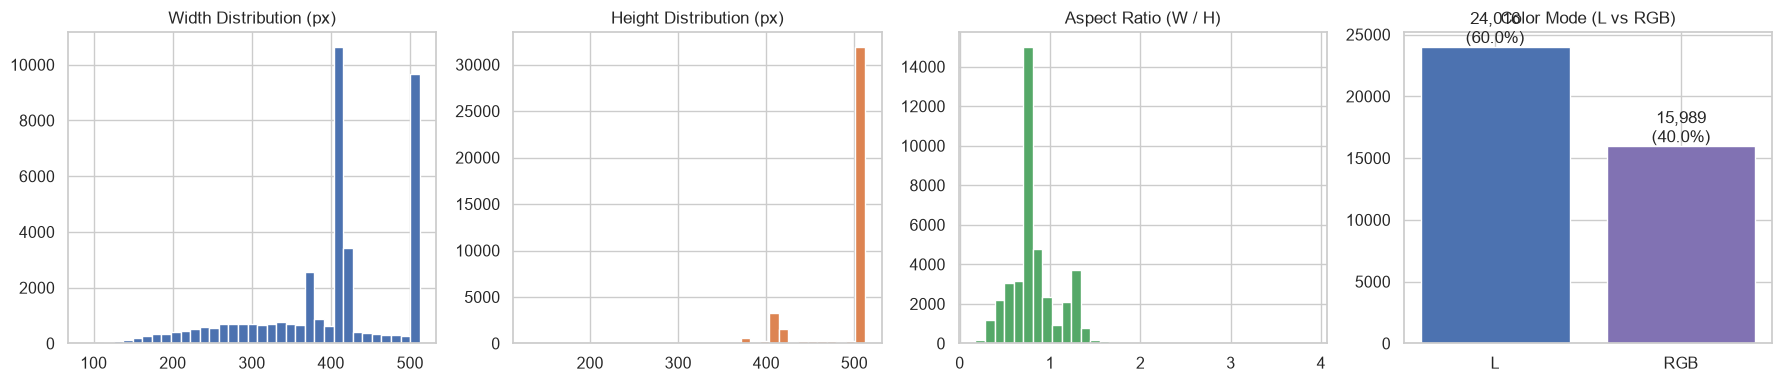

In [5]:
# Inspect every single image header across all 40,005 MURA PNGs
all_df = pd.concat([
    df_train_raw.assign(official_split="train"),
    df_valid_raw.assign(official_split="valid"),
], ignore_index=True)

def _scan_header(row):
    path = row["abs_path"]
    try:
        with Image.open(path) as im:
            w, h = im.size
            mode = im.mode
        fsize = os.path.getsize(path)
        return (w, h, mode, fsize, None)
    except Exception as exc:
        return (None, None, None, None, str(exc))

with ThreadPoolExecutor(max_workers=16) as ex:
    meta_rows = list(ex.map(_scan_header, [r for _, r in all_df[["abs_path"]].iterrows()]))

meta_df = pd.DataFrame(meta_rows, columns=["width", "height", "mode", "bytes", "error"])
all_meta = pd.concat([all_df, meta_df], axis=1)
all_meta["aspect_ratio"] = all_meta["width"] / all_meta["height"]

print(f"Corrupted / unreadable images: {all_meta['error'].notna().sum()} / {len(all_meta):,}")
print("\nColor modes across all 40,005 images:")
print(all_meta["mode"].value_counts().to_string())
print("\nDimension & Aspect-Ratio Summary:")
print(all_meta[["width", "height", "aspect_ratio"]].describe().round(2).to_string())
print(f"\nDimension outliers: width < 150 px = {(all_meta['width'] < 150).sum()}, "
      f"height < 200 px = {(all_meta['height'] < 200).sum()}")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].hist(all_meta["width"], bins=35, color="#4C72B0", edgecolor="white")
axes[0].set_title("Width Distribution (px)")
axes[1].hist(all_meta["height"], bins=35, color="#DD8452", edgecolor="white")
axes[1].set_title("Height Distribution (px)")
axes[2].hist(all_meta["aspect_ratio"], bins=35, color="#55A868", edgecolor="white")
axes[2].set_title("Aspect Ratio (W / H)")
mode_counts = all_meta["mode"].value_counts()
axes[3].bar(mode_counts.index, mode_counts.values, color=["#4C72B0", "#8172B3"])
axes[3].set_title("Color Mode (L vs RGB)")
for i, val in enumerate(mode_counts.values):
    axes[3].text(i, val + 300, f"{val:,}\n({val/len(all_meta)*100:.1f}%)", ha="center")

plt.tight_layout()
plt.savefig(EXP_DIR / "eda_image_properties.png", dpi=150, bbox_inches="tight")
plt.show()

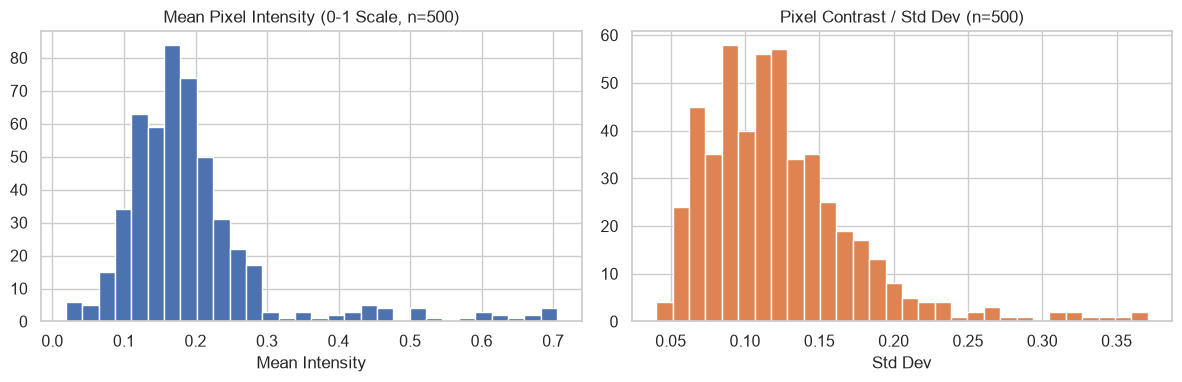

Mean intensity: min=0.019, median=0.173, max=0.705
Std  intensity: min=0.040, median=0.115, max=0.371


In [6]:
# Sample pixel intensity statistics (500 stratified images from train)
sample_paths = df_train_raw.sample(500, random_state=42)["abs_path"].tolist()
means, stds = [], []
for p in sample_paths:
    with Image.open(p) as im:
        arr = np.asarray(im.convert("L"), dtype=np.float32) / 255.0
        means.append(float(arr.mean()))
        stds.append(float(arr.std()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(means, bins=30, color="#4C72B0", edgecolor="white")
axes[0].set_title("Mean Pixel Intensity (0-1 Scale, n=500)")
axes[0].set_xlabel("Mean Intensity")
axes[1].hist(stds, bins=30, color="#DD8452", edgecolor="white")
axes[1].set_title("Pixel Contrast / Std Dev (n=500)")
axes[1].set_xlabel("Std Dev")
plt.tight_layout()
plt.savefig(EXP_DIR / "eda_pixel_intensity.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Mean intensity: min={min(means):.3f}, median={np.median(means):.3f}, max={max(means):.3f}")
print(f"Std  intensity: min={min(stds):.3f}, median={np.median(stds):.3f}, max={max(stds):.3f}")

## 6. Sample Radiographs per Class Across Body Parts

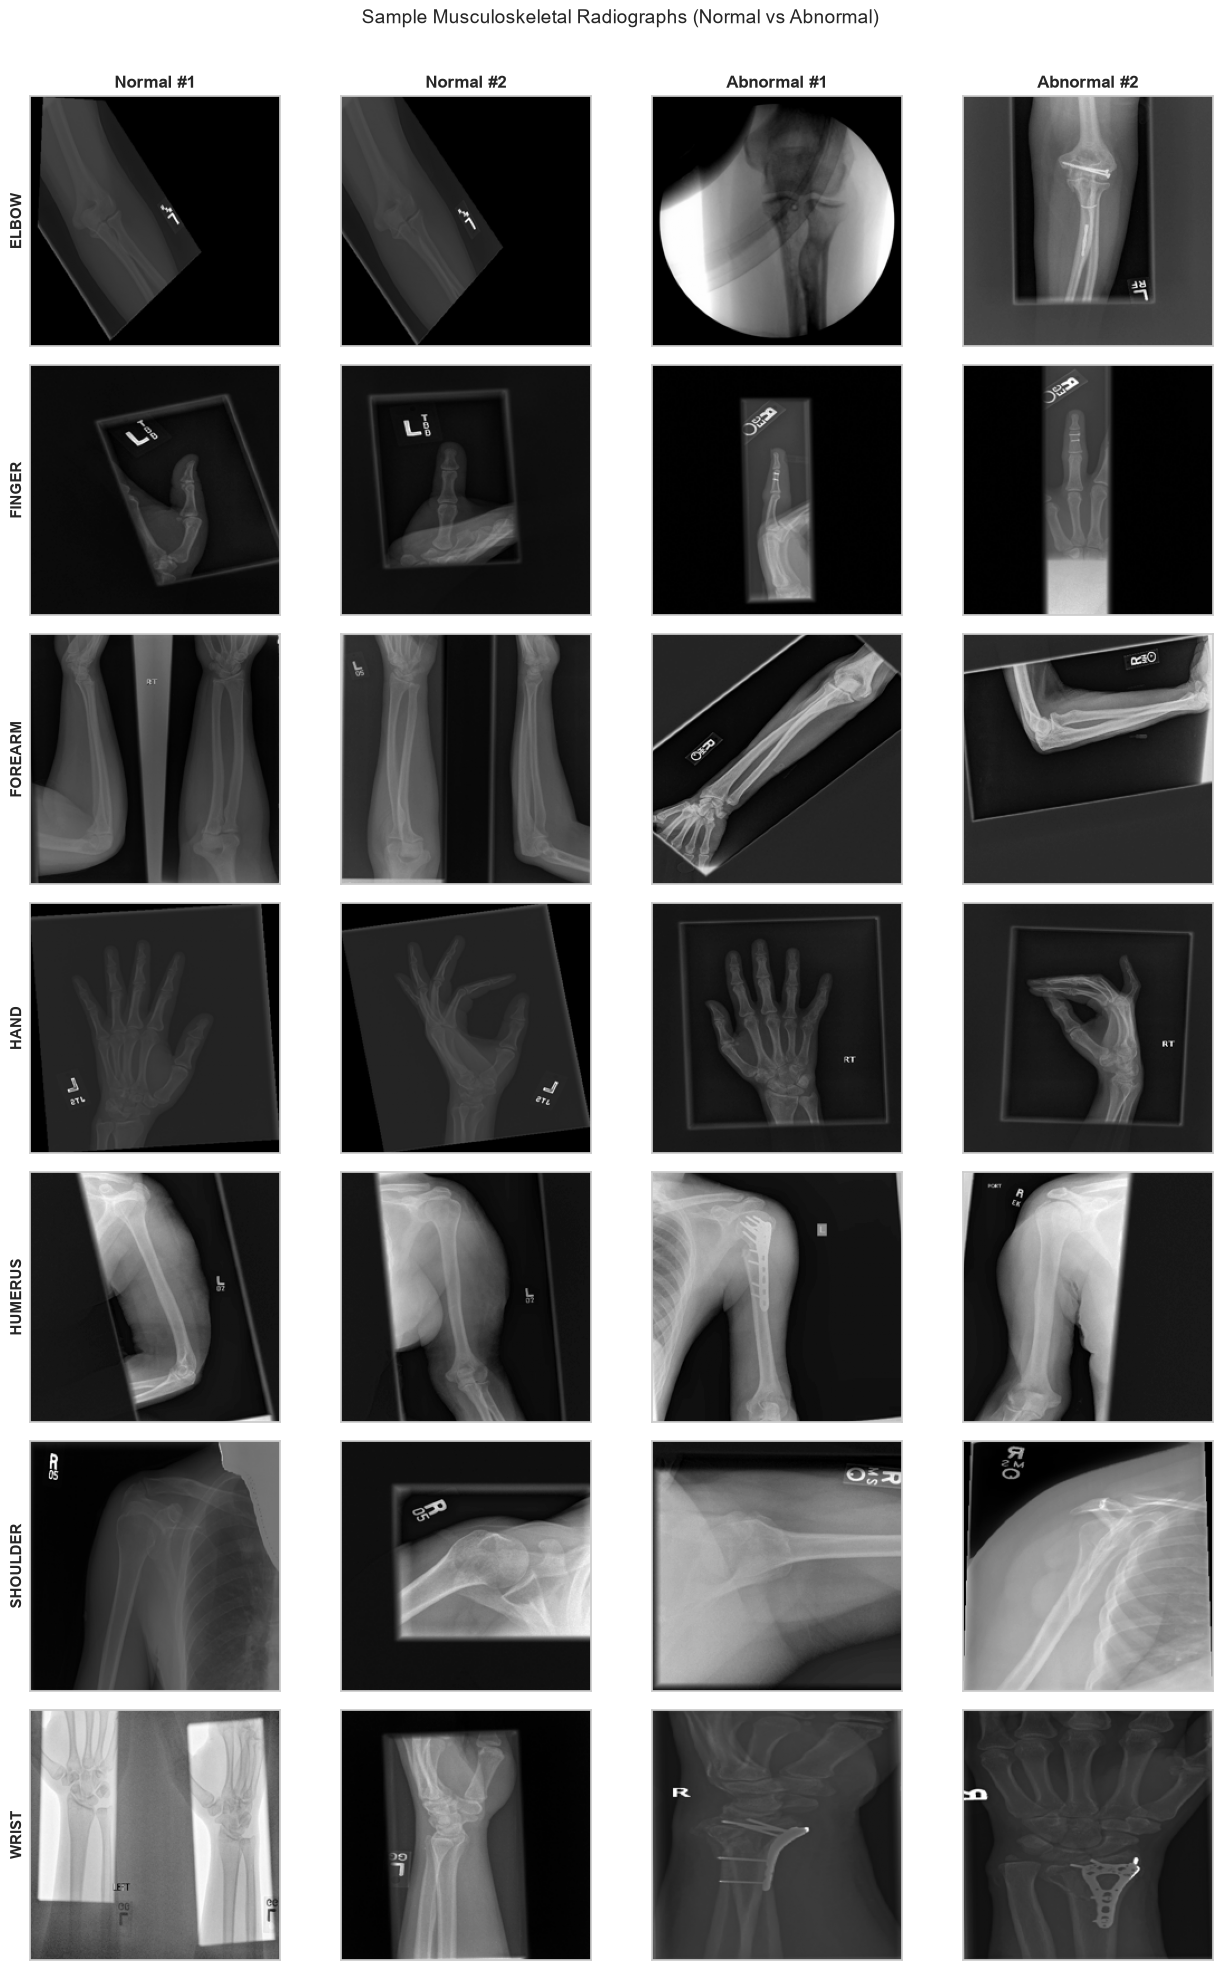

In [7]:
body_parts = sorted(df_train_raw["body_part"].unique())
fig, axes = plt.subplots(len(body_parts), 4, figsize=(13, 2.8 * len(body_parts)))

for row, bp in enumerate(body_parts):
    sub = df_train_raw[df_train_raw["body_part"] == bp]
    norm_sub = sub[sub["label"] == 0]
    abn_sub = sub[sub["label"] == 1]
    picks = [
        ("Normal", norm_sub.iloc[0]["abs_path"]),
        ("Normal", norm_sub.iloc[1]["abs_path"]),
        ("Abnormal", abn_sub.iloc[0]["abs_path"]),
        ("Abnormal", abn_sub.iloc[1]["abs_path"]),
    ]
    for col, (lbl_name, p) in enumerate(picks):
        with Image.open(p) as im:
            axes[row, col].imshow(im.convert("L").resize((224, 224)), cmap="gray")
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
        if row == 0:
            axes[row, col].set_title(f"{lbl_name} #{(col % 2) + 1}", fontweight="bold")
    axes[row, 0].set_ylabel(bp.replace("XR_", ""), fontsize=11, fontweight="bold")

plt.suptitle("Sample Musculoskeletal Radiographs (Normal vs Abnormal)", fontsize=14, y=1.005)
plt.tight_layout()
plt.savefig(EXP_DIR / "eda_sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Data Quality, Missing Values & Byte-Hash Duplicate Audit

In [8]:
# Audit byte-identical PNG files across all 40,005 images using size prefilter + MD5
def _md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(65536), b""):
            h.update(chunk)
    return h.hexdigest()

size_coll = all_meta[all_meta["bytes"].duplicated(keep=False)].copy()
with ThreadPoolExecutor(max_workers=8) as ex:
    size_coll["md5"] = list(ex.map(_md5, size_coll["abs_path"]))

exact_dups = size_coll[size_coll["md5"].duplicated(keep=False)].sort_values("md5")
print(f"Exact byte-identical duplicate records found across all 40,005 images: {len(exact_dups)} rows "
      f"({exact_dups['md5'].nunique()} unique duplicate hashes)")
print(exact_dups[["official_split", "body_part", "patient_id", "study_id", "label", "md5"]].to_string(index=False))

# Apply src.data.clean_dataframe to train
df_train_clean, clean_report = clean_dataframe(df_train_raw.copy(), check_files=True, deduplicate_content=True)
print("\nCleaning Report (Official Train):")
for k, v in clean_report.items():
    print(f"  {k}: {v}")

Exact byte-identical duplicate records found across all 40,005 images: 10 rows (5 unique duplicate hashes)
official_split body_part   patient_id                               study_id  label                              md5
         train  XR_WRIST patient07840  XR_WRIST/patient07840/study1_negative      0 508f07fddfb6bfd186cd9b546c9f6a86
         train  XR_WRIST patient07840  XR_WRIST/patient07840/study2_negative      0 508f07fddfb6bfd186cd9b546c9f6a86
         train  XR_WRIST patient06960  XR_WRIST/patient06960/study2_negative      0 51fd0e97ff772b09f45cc11a821442aa
         valid  XR_WRIST patient11359  XR_WRIST/patient11359/study1_negative      0 51fd0e97ff772b09f45cc11a821442aa
         train XR_FINGER patient04009 XR_FINGER/patient04009/study1_negative      0 603e8d33d576358322fd74c4c89d1724
         train XR_FINGER patient04296 XR_FINGER/patient04296/study1_negative      0 603e8d33d576358322fd74c4c89d1724
         train  XR_WRIST patient08556  XR_WRIST/patient08556/study1_negati


Cleaning Report (Official Train):
  initial_rows: 36808
  duplicates_removed: 0
  missing_values: {'image_path': 0, 'body_part': 0, 'patient_id': 0, 'study_id': 0, 'study_path': 0, 'label': 0, 'abs_path': 0}
  missing_files_removed: 0
  content_duplicates_removed: 4
  final_rows: 36804


## 8. Summary of EDA Findings → Modelling Decisions

| # | Empirical Finding | Modelling / Pipeline Decision |
|---|---|---|
| 1 | **Class imbalance:** Official train has 59.6% Normal vs 40.4% Abnormal images (61.5% vs 38.5% at study level). | Use Cohen's $\kappa$, Abnormal Recall & Macro-F1 instead of raw accuracy; apply training-only `class_weight='balanced'`. |
| 2 | **Multi-study & multi-body-part patients:** 1,467 patients span multiple body parts; studies average 2.65 views (Normal) vs 2.87 views (Abnormal), $r=+0.123$. | Include `body_part` in `study_id`; split strictly by `patient_id` (zero overlap) and stratify jointly by `(body_part, label)`. |
| 3 | **Wide abnormality variance by anatomy:** `XR_HAND` is 26.8% abnormal vs `XR_SHOULDER` at 49.7% abnormal. | Stratify by body part during splitting and track per-body-part metrics in Checkpoint 4 error analysis. |
| 4 | **Variable dimensions & aspect ratios:** Long edge capped at 512 px, short edge down to 89 px (`aspect_ratio` 0.17–3.88). | Standardize input to `(224, 224)` and apply training-only geometric augmentations (`RandomFlip`, `RandomRotation`, `RandomZoom`, `RandomTranslation`). |
| 5 | **Mixed color channels:** 60.0% of PNGs are 8-bit grayscale (`L`) and 40.0% are `RGB`. | Decode all radiographs uniformly to 3-channel RGB `(224, 224, 3)` for CNNs and grayscale (`L`) for flattened pixel baselines. |
| 6 | **Byte-identical duplicate images:** 4 extra exact MD5 duplicates in `train` (including cross-patient duplicates `patient04009`/`patient04296` and `patient08556`/`patient08915`). | Deduplicate both `image_path` and MD5 content in `clean_dataframe()` before splitting so identical scans cannot leak across splits. |

## 9. Leak-Free Preprocessing & Split Validation (70 / 15 / 15)

              Split  Images  Patients  Abnormal %
        Train (70%)   25773      7827       40.43
          Val (15%)    5477      1678       40.57
Test (15% - locked)    5554      1678       40.19

[OK] Zero patient overlap verified across Train / Val / Test.
Training-only balanced class weights: Normal(0)=0.8393, Abnormal(1)=1.2368


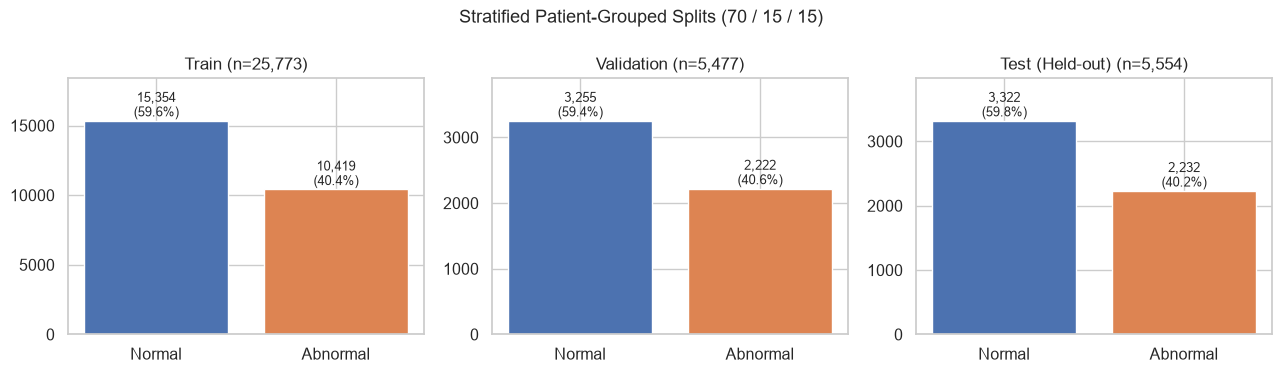

In [9]:
train_split, val_split, test_split = patient_stratified_split(
    df_train_clean,
    val_frac=cfg["split"]["val_fraction"],
    test_frac=cfg["split"]["test_fraction"],
    seed=cfg["split"]["random_seed"],
)

p_tr = set(train_split["patient_id"])
p_va = set(val_split["patient_id"])
p_te = set(test_split["patient_id"])
assert p_tr.isdisjoint(p_va) and p_tr.isdisjoint(p_te) and p_va.isdisjoint(p_te)

split_summary = pd.DataFrame([
    {"Split": "Train (70%)", "Images": len(train_split), "Patients": len(p_tr), "Abnormal %": round(train_split["label"].mean()*100, 2)},
    {"Split": "Val (15%)",   "Images": len(val_split),   "Patients": len(p_va), "Abnormal %": round(val_split["label"].mean()*100, 2)},
    {"Split": "Test (15% - locked)", "Images": len(test_split), "Patients": len(p_te), "Abnormal %": round(test_split["label"].mean()*100, 2)},
])
print(split_summary.to_string(index=False))
print("\n[OK] Zero patient overlap verified across Train / Val / Test.")

cw = compute_weights(train_split)
print(f"Training-only balanced class weights: Normal(0)={cw[0]:.4f}, Abnormal(1)={cw[1]:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, sdf) in zip(axes, [("Train", train_split), ("Validation", val_split), ("Test (Held-out)", test_split)]):
    vc = sdf["label"].value_counts().sort_index()
    bars = ax.bar(["Normal", "Abnormal"], vc.values, color=["#4C72B0", "#DD8452"])
    ax.set_title(f"{name} (n={len(sdf):,})")
    ax.set_ylim(0, vc.max() * 1.2)
    for bar, val in zip(bars, vc.values):
        ax.text(bar.get_x() + bar.get_width()/2, val + vc.max()*0.02,
                f"{val:,}\n({val/len(sdf)*100:.1f}%)", ha="center", fontsize=9)
plt.suptitle("Stratified Patient-Grouped Splits (70 / 15 / 15)", fontsize=13)
plt.tight_layout()
plt.savefig(EXP_DIR / "eda_split_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Baseline Benchmark Evaluation (Validation Split Only)

                             accuracy  normal_recall  precision  recall      f1  macro_f1   kappa     auc  study_kappa  study_auc
model                                                                                                                            
MajorityBaseline               0.5943         1.0000     0.0000  0.0000  0.0000    0.3728  0.0000  0.5000       0.0000     0.5000
LogisticBaseline_unweighted    0.5759         0.8037     0.4571  0.2421  0.3166    0.5045  0.0495  0.5415       0.0406     0.5552
LogisticBaseline_balanced      0.5348         0.5558     0.4365  0.5041  0.4678    0.5273  0.0584  0.5412       0.0808     0.5547


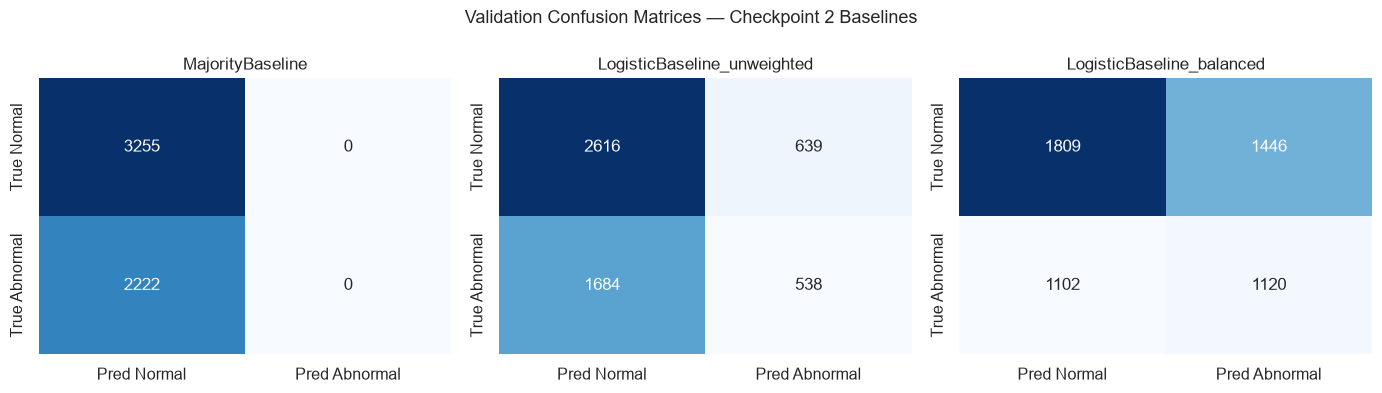

In [10]:
X_train, y_train = load_flattened_images(train_split, size=(64, 64))
X_val, y_val = load_flattened_images(val_split, size=(64, 64))

baselines = [
    MajorityBaseline(),
    LogisticBaseline(C=0.01, max_iter=1000, class_weight=None, seed=42),
    LogisticBaseline(C=0.01, max_iter=1000, class_weight="balanced", seed=42),
]

rows = []
cms = []
for model in baselines:
    model.fit(X_train, y_train)
    m = model.evaluate(X_val, y_val)
    probs = model.predict_proba(X_val)[:, 1]
    preds = model.predict(X_val)
    st_m = evaluate_study_level(val_split, probs)
    m["study_kappa"] = st_m["kappa"]
    m["study_auc"] = st_m["auc"]
    rows.append(m)
    cms.append((model.name, get_confusion_matrix(y_val, preds)))

results_df = pd.DataFrame(rows).set_index("model").round(4)
print(results_df.to_string())
results_df.to_csv(EXP_DIR / "baseline_results.csv")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, cm) in zip(axes, cms):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred Normal", "Pred Abnormal"],
                yticklabels=["True Normal", "True Abnormal"])
    ax.set_title(name)
plt.suptitle("Validation Confusion Matrices — Checkpoint 2 Baselines", fontsize=13)
plt.tight_layout()
plt.savefig(EXP_DIR / "baseline_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Baseline Interpretation

1. **MajorityBaseline** achieves 59.43% accuracy simply by predicting every radiograph Normal, yielding **0.0000 Abnormal Recall** and **Cohen's $\kappa = 0.0000$** — confirming raw accuracy is unfit for clinical triage.
2. **LogisticBaseline (unweighted)** achieves modest linear separation ($\kappa = 0.0495$, ROC-AUC $= 0.5415$), heavily skewed toward Normal Recall (80.37%) at the expense of Abnormal Recall (24.21%).
3. **LogisticBaseline (balanced)** applies inverse-frequency class weights from the training split, boosting **Abnormal Recall from 24.21% to 50.41%** (+26.20 percentage points) and raising both **Macro-F1** (0.5045 $\to$ 0.5273) and **$\kappa$** (0.0495 $\to$ 0.0584; study-level $\kappa = 0.0808$).
4. Overall linear pixel performance remains low ($\kappa < 0.10$) because bone fractures and joint abnormalities depend on **local spatial patterns** regardless of exact pixel coordinates — justifying convolutional neural networks (Custom CNN + ResNet-50 transfer learning) in Checkpoint 3.